In [1]:
# =========================================================================
#  DEPENDENCIAS — EJECUTAR ESTA CELDA PRIMERO
# -------------------------------------------------------------------------
#  Revisa paquete por paquete e instala UNICAMENTE los que falten.
#  En Google Colab casi todos vienen preinstalados, asi que lo normal es
#  que esta celda no descargue nada y termine en un segundo.
# =========================================================================
import importlib.metadata as metadata
import importlib.util
import subprocess
import sys

# modulo que se importa  ->  nombre con el que se instala desde pip
REQUISITOS = {
    "numpy": "numpy",                     # arreglos numericos
    "pandas": "pandas",                   # dataframes tabulares
    "pyarrow": "pyarrow",                 # lectura/escritura de .parquet
    "sklearn": "scikit-learn",            # splits, scaler, PCA, t-SNE, K-Means
    "matplotlib": "matplotlib",           # graficos del EDA
    "psutil": "psutil",                   # medicion de RAM
    "joblib": "joblib",                   # guardado del StandardScaler
    "torch": "torch",                     # tensores y redes neuronales
    "ydata_profiling": "ydata-profiling",  # auditoria de particiones
}

faltantes = [pip_name for modulo, pip_name in REQUISITOS.items()
             if importlib.util.find_spec(modulo) is None]

if faltantes:
    print(f"Faltan {len(faltantes)} paquete(s): {', '.join(faltantes)}")
    print("Instalando (puede tardar un par de minutos)...\n")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltantes], check=True)
    print("\nInstalacion terminada.")
    print("Si Colab pide REINICIAR el entorno de ejecucion, reinicia y vuelve a")
    print("ejecutar desde aqui: la descarga del dataset se reanuda sola.")
else:
    print("Todas las dependencias ya estaban instaladas: no se descargo nada.")

print("\nVersiones en uso")
print("-" * 36)
for pip_name in REQUISITOS.values():
    try:
        print(f"  {pip_name:<18} {metadata.version(pip_name)}")
    except metadata.PackageNotFoundError:
        print(f"  {pip_name:<18} (no detectada)")

Todas las dependencias ya estaban instaladas: no se descargo nada.

Versiones en uso
------------------------------------
  numpy              2.3.5
  pandas             2.3.3
  pyarrow            26.0.1
  scikit-learn       1.9.1
  matplotlib         3.10.0
  psutil             5.9.8
  joblib             1.6.0
  torch              2.15.0
  ydata-profiling    4.18.4


# Laboratorio 1 — Fase A: Carga Masiva, Particiones y Análisis Exploratorio
### Opción B: Predicción Científica — *HIGGS Boson Dataset* (UCI Machine Learning Repository)

**Curso:** Fundamentos de Aprendizaje Profundo y Aplicaciones — 2-2026
**Grupo:** 6 · **Integrante:** Cristopher Angulo Ahumada (trabajo individual)

---

## 1. Justificación del dataset y del problema científico

El **HIGGS Boson Dataset** (Baldi, Sadowski & Whiteson, *Nature Communications* 5, 2014) contiene
**11.000.000 de colisiones simuladas** de partículas en un acelerador. La tarea es de
**clasificación binaria**: distinguir un evento de **señal** —producción de un bosón de Higgs— de
un evento de **fondo**, entendido como un proceso físico distinto que genera exactamente los
mismos productos de decaimiento observables.

El problema reúne las tres características que justifican el uso de aprendizaje profundo. Las
variables son continuas y están fuertemente correlacionadas entre sí; las diferencias entre ambas
clases son sutiles y no se manifiestan en ninguna variable aislada; y el volumen disponible permite
ajustar modelos de alta capacidad sin incurrir de inmediato en sobreajuste. Es, además, el escenario
en el que el trabajo original demostró que una red profunda supera a los métodos tradicionales de
la física de altas energías.

### 1.1 Descripción de las variables

La primera columna del archivo contiene la **etiqueta** y las 28 siguientes son las variables
predictoras.

| # | Columna | Descripción |
|---|---|---|
| 0 | `label` | **Variable objetivo.** `1` = señal (la colisión produjo un bosón de Higgs); `0` = fondo (otro proceso físico que deja los mismos productos observables) |

#### Variables cinemáticas de bajo nivel (21): medición directa del detector

Caracterizan la trayectoria y la energía de cada partícula detectada. Cada objeto requiere tres
magnitudes: su momento transversal (`pt`), su inclinación respecto al eje del haz (`eta`) y su
orientación dentro del plano transversal (`phi`).

| # | Columna | Descripción |
|---|---|---|
| 1 | `lepton_pT` | Momento transversal del leptón (electrón o muón): momento proyectado sobre el plano perpendicular al haz. Es la magnitud que mejor cuantifica la energía transportada por la partícula |
| 2 | `lepton_eta` | Pseudorapidez del leptón: inclinación de su trayectoria respecto al eje del haz. η = 0 corresponde a una trayectoria perpendicular al haz; valores elevados indican emisión casi paralela a él |
| 3 | `lepton_phi` | Ángulo azimutal del leptón: orientación dentro del plano transversal |
| 4 | `missing_energy_magnitude` | Energía transversal faltante. Dado que el momento total debe conservarse, un desbalance evidencia partículas que atravesaron el detector sin interactuar, típicamente neutrinos |
| 5 | `missing_energy_phi` | Orientación azimutal de la energía faltante |
| 6 | `jet1_pt` | Momento transversal del jet 1. Un *jet* es la cascada de partículas originada por un quark o un gluón; los jets se presentan ordenados de mayor a menor momento |
| 7 | `jet1_eta` | Pseudorapidez del jet 1 |
| 8 | `jet1_phi` | Ángulo azimutal del jet 1 |
| 9 | `jet1_b_tag` | Etiquetado *b* del jet 1: indica si el jet proviene probablemente de un quark *bottom*. Es una variable crítica, dado que el bosón de Higgs decae preferentemente a un par de quarks *b* |
| 10 | `jet2_pt` | Momento transversal del jet 2 |
| 11 | `jet2_eta` | Pseudorapidez del jet 2 |
| 12 | `jet2_phi` | Ángulo azimutal del jet 2 |
| 13 | `jet2_b_tag` | Etiquetado *b* del jet 2 |
| 14 | `jet3_pt` | Momento transversal del jet 3 |
| 15 | `jet3_eta` | Pseudorapidez del jet 3 |
| 16 | `jet3_phi` | Ángulo azimutal del jet 3 |
| 17 | `jet3_b_tag` | Etiquetado *b* del jet 3 |
| 18 | `jet4_pt` | Momento transversal del jet 4 |
| 19 | `jet4_eta` | Pseudorapidez del jet 4 |
| 20 | `jet4_phi` | Ángulo azimutal del jet 4 |
| 21 | `jet4_b_tag` | Etiquetado *b* del jet 4 |

#### Variables derivadas de alto nivel (7): construidas por especialistas del dominio

No incorporan información nueva: son **funciones de las 21 variables anteriores**. Corresponden a
*masas invariantes*, es decir, a la masa que debería haber tenido la partícula original para
producir ese conjunto de productos de decaimiento. Si en un evento los productos son compatibles con
la masa de un bosón W, de un quark top o del bosón de Higgs, esa compatibilidad se manifiesta en
estas variables y no en las magnitudes crudas.

| # | Columna | Descripción |
|---|---|---|
| 22 | `m_jj` | Masa invariante de dos jets ligeros: reconstruye el bosón **W** con decaimiento hadrónico |
| 23 | `m_jjj` | Masa invariante de tres jets: reconstruye el quark **top** hadrónico |
| 24 | `m_lv` | Masa invariante del sistema leptón + neutrino (energía faltante): bosón **W** con decaimiento leptónico |
| 25 | `m_jlv` | Masa invariante del sistema jet + leptón + neutrino: quark **top** leptónico |
| 26 | `m_bb` | Masa invariante de los dos jets *b*. **La variable más discriminante del conjunto**: en los eventos de señal reconstruye el **bosón de Higgs**, que decae a un par b-antib |
| 27 | `m_wbb` | Masa invariante del sistema W + dos jets *b* |
| 28 | `m_wwbb` | Masa invariante del sistema completo: dos bosones W más los dos jets *b* |

> **Unidades.** Los valores del archivo original están previamente reescalados, por lo que los
> momentos y las masas no se expresan directamente en GeV. Los rangos efectivos de cada variable
> se reportan en la salida de `describe()` de la Celda 4.

## 2. Cumplimiento de los requisitos del enunciado

| Requisito | Cumplimiento |
|---|---|
| Volumen: 200.000 – 1.000.000 registros | ✅ Se extrae una **submuestra aleatoria de 1.000.000 de filas** sobre los 11.000.000 originales |
| Dimensionalidad: ≥ 40 columnas | ⚠️ El dataset aporta **28 variables**. El profesor autorizó expresamente su uso en estas condiciones, dado que el volumen de observaciones compensa la menor dimensionalidad; el enunciado lo incluye además como ejemplo explícito de la Opción B. En la Fase B el *feature engineering* eleva el conjunto a **51 variables**, superando el mínimo |
| Análisis exploratorio y no supervisado sobre submuestra del 10 % | ✅ Se ejecuta sobre 100.000 filas |
| Auditoría de particiones con `ydata-profiling` | ✅ `compare([train, val, test])` con `minimal=True` |
| Gestión activa de memoria | ✅ Lectura por bloques, casteo a `float32`, persistencia en `.parquet`, liberación explícita con `del` y `gc.collect()` |
| Checkpoints en Google Drive | ✅ Cuando hay Drive disponible —Colab o la aplicación de escritorio— los artefactos pesados se escriben allí; en su defecto, quedan en el repositorio |

## 3. Productos de este notebook

| Artefacto | Contenido |
|---|---|
| `higgs_1M.parquet` | Submuestra de 1.000.000 de filas en formato columnar comprimido |
| `splits_escalados.npz` | Particiones Train / Validation / Test escaladas, sin *data leakage* |
| `scaler.joblib` | El `StandardScaler` ajustado exclusivamente con el conjunto de entrenamiento |
| `reports/profiling/comparacion_particiones.html` | Auditoría comparativa de particiones exigida en los entregables |
| `reports/figures/*.png` | Seis figuras del análisis exploratorio y no supervisado |

---
# Celda 1 — Imports, reproducibilidad y utilidades de memoria

In [2]:
# Incrusta las figuras en las salidas del notebook.
# Sin esto, en este entorno el backend por defecto es `tkagg`: plt.show()
# intenta abrir una ventana y los graficos NO quedan guardados en el .ipynb,
# que es justamente lo que hay que entregar.
%matplotlib inline

import gc
import shutil
import os
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import torch

warnings.filterwarnings("ignore")

SEED = 42


def set_seed(seed: int = SEED) -> None:
    '''Fija todas las fuentes de aleatoriedad para que el experimento sea reproducible.'''
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")


def mem_report(tag: str = "") -> None:
    '''Reporta el consumo de RAM del proceso y del sistema.

    La gestion de memoria es un criterio explicito de la rubrica: en Colab disponemos de ~12 GB
    y el dataset original pesa 7.5 GB sin comprimir, por lo que NUNCA se carga completo.
    '''
    rss = psutil.Process(os.getpid()).memory_info().rss / 1e9
    vm = psutil.virtual_memory()
    print(f"[RAM] {tag:<34} proceso: {rss:5.2f} GB | sistema: {vm.used/1e9:5.2f}/{vm.total/1e9:.2f} GB ({vm.percent:.0f}%)")


mem_report("inicio")

Dispositivo: cpu
[RAM] inicio                             proceso:  0.32 GB | sistema: 19.89/34.16 GB (58%)


---
# Celda 2 — Entorno de ejecución y rutas del proyecto

El notebook se adapta a tres escenarios de ejecución sin requerir modificaciones en el código:

| Escenario | Destino de los artefactos pesados |
|---|---|
| **Google Colab** | Google Drive, montado en `/content/drive` |
| **Local con Google Drive para escritorio** | La unidad sincronizada (`G:\Mi unidad\Lab1-DL`) |
| **Local sin Drive** | El propio repositorio, en carpetas excluidas por `.gitignore` |

En los dos primeros casos los checkpoints quedan en Drive, que es precisamente lo que exige el
enunciado: que una interrupción a mitad del entrenamiento no obligue a reiniciarlo desde cero.

## Política de almacenamiento

Los artefactos se distribuyen según su función.

**Archivos pesados** —la submuestra en `.parquet` (62,6 MB), las particiones escaladas (113 MB) y
los pesos `.pt`— se escriben en Drive. Su propósito es sobrevivir a una caída de sesión, y además
no son versionables: el archivo de particiones excede por sí solo el límite de 100 MB por archivo
que impone GitHub, y todos ellos se regeneran de forma determinista a partir del código y las
semillas fijadas.

**Evidencia del informe** —figuras, tablas y el reporte de profiling— se guarda en **los dos
destinos**: el repositorio, donde queda versionada y por donde se revisa el trabajo, y Drive, que
conserva la copia de respaldo junto al resto de los artefactos. El repositorio es el destino
primario y la réplica se realiza archivo por archivo en el momento de escribirlo, mediante la
función `espejar()`, de modo que una interrupción no deje el respaldo incompleto.

El archivo `.csv.gz` de 2,6 GB constituye la excepción y se almacena invariablemente en disco
local: es un insumo temporal que se lee una sola vez, y sincronizarlo a Drive consumiría cuota sin
beneficio alguno.

In [3]:
# -------------------------------------------------------------------------
#  Deteccion del entorno y ubicacion de los artefactos
# -------------------------------------------------------------------------
# Nota: no sirve importlib.util.find_spec("google.colab"), porque LANZA
# ModuleNotFoundError cuando el paquete padre `google` no existe (solo
# devuelve None si existe `google` pero le falta `colab`). Se comprueba
# intentando la importacion, que es barata cuando falla.
try:
    import google.colab  # noqa: F401

    EN_COLAB = True
except ModuleNotFoundError:
    EN_COLAB = False


def raiz_del_repo():
    """Carpeta Lab1-DL, se ejecute el notebook desde notebooks/ o desde la raiz."""
    actual = Path.cwd().resolve()
    for candidata in (actual, *actual.parents):
        if (candidata / "src").is_dir() and (candidata / "notebooks").is_dir():
            return candidata
    return actual


def buscar_drive_local():
    """Ubica 'Mi unidad' de Google Drive para escritorio, si esta montado."""
    for letra in "GHIJKLDEF":
        for nombre in ("Mi unidad", "My Drive"):
            ruta = Path(f"{letra}:/{nombre}")
            try:
                if ruta.is_dir():
                    return ruta
            except OSError:
                continue
    return None


REPO = raiz_del_repo()

if EN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/Lab1-DL")
    RAW_GZ = Path("/content/HIGGS.csv.gz")       # disco efimero de Colab
    ENTORNO = "Google Colab, con Drive montado"
else:
    unidad = buscar_drive_local()
    if unidad is not None:
        PROJECT_DIR = unidad / "Lab1-DL"
        ENTORNO = f"Local, con Google Drive para escritorio en {unidad}"
    else:
        PROJECT_DIR = REPO
        ENTORNO = "Local, sin Drive: los artefactos quedan en el repositorio"
    # El .gz de 2.6 GB nunca va a Drive: se lee una vez y es descartable.
    RAW_GZ = REPO / "data" / "raw" / "HIGGS.csv.gz"

PROC_DIR = PROJECT_DIR / "data" / "processed"    # parquet y splits escalados
CKPT_DIR = PROJECT_DIR / "checkpoints"           # pesos .pt (notebooks 02 y 03)
# Los artefactos pesados (parquet, splits, checkpoints) van a Drive, porque su
# razon de ser es sobrevivir a una interrupcion.
#
# La evidencia del informe (figuras, tablas y el reporte de profiling) pesa poco
# y se guarda en LOS DOS destinos: el repositorio, que es donde se versiona y
# por donde se revisa el trabajo, y Drive, que conserva la copia de respaldo
# junto al resto de los artefactos. El repositorio es el destino primario y la
# copia a Drive se hace archivo por archivo en cuanto cada uno se escribe, de
# modo que una interrupcion no deje el respaldo a medias.
REPORT_DIR = REPO / "reports"
FIG_DIR = REPORT_DIR / "figures"          # figuras .png
PROFILING_DIR = REPORT_DIR / "profiling"  # reporte html de ydata-profiling
TABLE_DIR = REPORT_DIR / "tables"         # tablas .csv

# Destinos de la evidencia: el primero es el primario; los siguientes, copias.
DIRS_INFORME = [REPORT_DIR]
if PROJECT_DIR != REPO:
    DIRS_INFORME.append(PROJECT_DIR / "reports")


def espejar(ruta: Path) -> list:
    """Replica en los destinos secundarios un archivo escrito en el primario."""
    copias = []
    for base in DIRS_INFORME[1:]:
        destino = base / ruta.relative_to(DIRS_INFORME[0])
        destino.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(ruta, destino)
        copias.append(destino)
    return copias


def guardar_figura(nombre: str, dpi: int = 120) -> Path:
    """Guarda la figura actual en el repositorio y la replica en Drive."""
    ruta = FIG_DIR / nombre
    plt.savefig(ruta, dpi=dpi, bbox_inches="tight")
    espejar(ruta)
    return ruta

for carpeta in (PROC_DIR, CKPT_DIR, RAW_GZ.parent):
    carpeta.mkdir(parents=True, exist_ok=True)
for base in DIRS_INFORME:
    for sub in ("figures", "profiling", "tables"):
        (base / sub).mkdir(parents=True, exist_ok=True)

PARQUET_PATH = PROC_DIR / "higgs_1M.parquet"
SPLITS_PATH = PROC_DIR / "splits_escalados.npz"
SCALER_PATH = PROC_DIR / "scaler.joblib"

print(f"Entorno detectado: {ENTORNO}\n")
print(f"  artefactos   -> {PROJECT_DIR}")
print(f"  procesados   -> {PROC_DIR}")
print(f"  checkpoints  -> {CKPT_DIR}")
print(f"  informe      -> {' | '.join(str(d) for d in DIRS_INFORME)}")
print(f"  dataset .gz  -> {RAW_GZ}")

if not EN_COLAB and buscar_drive_local() is None:
    print("\nAVISO: no se detecto Google Drive para escritorio.")
    print("Para que los checkpoints queden en Drive, instala la app desde")
    print("https://www.google.com/drive/download/ , inicia sesion y re-ejecuta")
    print("esta celda: la unidad sincronizada se detecta sola.")


Entorno detectado: Local, con Google Drive para escritorio en G:\Mi unidad

  artefactos   -> G:\Mi unidad\Lab1-DL
  procesados   -> G:\Mi unidad\Lab1-DL\data\processed
  checkpoints  -> G:\Mi unidad\Lab1-DL\checkpoints
  informe      -> C:\Users\Admin\Desktop\Magister Informatica\Aprendizaje Profundo\Lab1-DL\reports | G:\Mi unidad\Lab1-DL\reports
  dataset .gz  -> C:\Users\Admin\Desktop\Magister Informatica\Aprendizaje Profundo\Lab1-DL\data\raw\HIGGS.csv.gz


---
# Celda 3 — Obtención del dataset (2,6 GB comprimidos)

La descarga se implementa en Python en lugar de delegarla a `wget`, que no forma parte de la
instalación estándar de Windows; de este modo el notebook es ejecutable en los tres entornos sin
dependencias externas.

La función **intenta** reanudar una descarga interrumpida solicitando el tramo pendiente mediante
la cabecera HTTP `Range`. Se verificó empíricamente que el servidor de UCI **no admite
reanudación**: responde con código `200` en lugar de `206`, lo que equivale a reiniciar la
transferencia. El impacto es acotado, dado que la velocidad medida en el equipo de trabajo es de
aproximadamente 17 MB/s y los 2,6 GB se transfieren en cerca de 3 minutos.

Si el archivo se encuentra completo en disco, la celda no realiza ninguna descarga.

In [4]:
import urllib.request

URL_HIGGS = "https://archive.ics.uci.edu/ml/machine-learning-databases/00280/HIGGS.csv.gz"
TAMANO_MINIMO = 2_500_000_000   # umbral para dar por completa la descarga (~2.6 GB)


def descargar_con_reanudacion(url, destino, intentos=5, bloque=1 << 20):
    """Descarga con reintentos, sin depender de wget.

    Si ya hay bytes en disco pide al servidor solo el tramo que falta (cabecera
    `Range`). Cuando el servidor no soporta reanudacion responde 200 en vez de
    206 y la descarga se reinicia desde cero: es el caso del servidor de UCI,
    verificado. Los reintentos sirven igual ante cortes de red transitorios.
    """
    destino = Path(destino)
    for intento in range(1, intentos + 1):
        descargado = destino.stat().st_size if destino.exists() else 0
        peticion = urllib.request.Request(url, headers={"User-Agent": "python-urllib"})
        if descargado:
            peticion.add_header("Range", f"bytes={descargado}-")
            print(f"Reanudando desde {descargado/1e9:.2f} GB (intento {intento}/{intentos})")

        try:
            with urllib.request.urlopen(peticion, timeout=120) as respuesta:
                if descargado and respuesta.status != 206:
                    print("  el servidor no acepto reanudar: se reinicia desde cero")
                    descargado = 0
                modo = "ab" if descargado else "wb"

                inicio = time.time()
                bytes_sesion = 0
                siguiente_aviso = 250 * (1 << 20)

                with open(destino, modo) as salida:
                    while True:
                        trozo = respuesta.read(bloque)
                        if not trozo:
                            break
                        salida.write(trozo)
                        bytes_sesion += len(trozo)
                        if bytes_sesion >= siguiente_aviso:
                            siguiente_aviso += 250 * (1 << 20)
                            total = (descargado + bytes_sesion) / 1e9
                            vel = bytes_sesion / max(time.time() - inicio, 1e-9) / 1e6
                            print(f"  {total:5.2f} GB descargados  ({vel:5.1f} MB/s)")
            return destino

        except Exception as error:
            print(f"  intento {intento} interrumpido: {type(error).__name__}: {error}")

    raise RuntimeError(f"No se pudo completar la descarga tras {intentos} intentos")


if RAW_GZ.exists() and RAW_GZ.stat().st_size >= TAMANO_MINIMO:
    print(f"Ya descargado: {RAW_GZ} ({RAW_GZ.stat().st_size/1e9:.2f} GB)")
else:
    t0 = time.time()
    descargar_con_reanudacion(URL_HIGGS, RAW_GZ)
    print(f"\nDescarga completada en {(time.time()-t0)/60:.1f} min")

print(f"Tamano final: {RAW_GZ.stat().st_size/1e9:.2f} GB")


Ya descargado: C:\Users\Admin\Desktop\Magister Informatica\Aprendizaje Profundo\Lab1-DL\data\raw\HIGGS.csv.gz (2.82 GB)
Tamano final: 2.82 GB


---
# Celda 4 — Carga por bloques y submuestreo a 1.000.000 de filas

Esta etapa concentra la mayor exigencia de memoria del laboratorio. El archivo descomprimido ocupa
aproximadamente 7,5 GB, por lo que leerlo íntegramente con una sola llamada a `pd.read_csv()`
provoca el agotamiento de la memoria disponible y el colapso de la sesión.

La estrategia adoptada consta de cuatro medidas:

1. **Lectura por bloques de 1.000.000 de filas** mediante el parámetro `chunksize`, de modo que en
   memoria no resida nunca más de un bloque a la vez.
2. **Casteo explícito a `float32`** en lugar del `float64` que pandas asume por defecto, lo que
   reduce a la mitad la memoria por valor sin pérdida relevante de precisión en variables que ya
   vienen reescaladas.
3. **Muestreo aleatorio del 9,09 % de cada bloque.** Al muestrear uniformemente en todos los
   bloques, la submuestra resultante de 1.000.000 de filas es representativa del dataset completo y
   no queda sesgada hacia el inicio del archivo. La precaución es necesaria porque el orden de las
   filas en HIGGS no es aleatorio: el benchmark original reserva las últimas 500.000 observaciones
   como conjunto de prueba.
4. **Liberación explícita de cada bloque** con `del` seguido de `gc.collect()` inmediatamente
   después de procesarlo.

In [5]:
COLUMNAS = [
    "label",
    "lepton_pT", "lepton_eta", "lepton_phi",
    "missing_energy_magnitude", "missing_energy_phi",
    "jet1_pt", "jet1_eta", "jet1_phi", "jet1_b_tag",
    "jet2_pt", "jet2_eta", "jet2_phi", "jet2_b_tag",
    "jet3_pt", "jet3_eta", "jet3_phi", "jet3_b_tag",
    "jet4_pt", "jet4_eta", "jet4_phi", "jet4_b_tag",
    "m_jj", "m_jjj", "m_lv", "m_jlv", "m_bb", "m_wbb", "m_wwbb",
]
FEATURES = COLUMNAS[1:]           # 28 variables predictoras
N_TOTAL = 11_000_000              # filas del dataset original
N_OBJETIVO = 1_000_000            # tope superior permitido por el enunciado
FRAC = N_OBJETIVO / N_TOTAL       # ~0.0909

if PARQUET_PATH.exists():
    print(f"Submuestra ya existe, se recarga desde disco: {PARQUET_PATH}")
    df = pd.read_parquet(PARQUET_PATH)
else:
    t0 = time.time()
    bloques = []
    lector = pd.read_csv(
        RAW_GZ,
        header=None,
        names=COLUMNAS,
        dtype=np.float32,
        chunksize=1_000_000,
        compression="gzip",
    )

    for i, bloque in enumerate(lector):
        bloques.append(bloque.sample(frac=FRAC, random_state=SEED + i))
        filas = sum(len(b) for b in bloques)
        print(f"  bloque {i+1:2d}/11 procesado | acumulado: {filas:,} filas | {time.time()-t0:5.0f}s")
        del bloque
        gc.collect()

    df = pd.concat(bloques, ignore_index=True)
    del bloques, lector
    gc.collect()

    # Mezcla final y tipos minimos
    df = df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
    df["label"] = df["label"].astype(np.int8)

    print(f"\nLectura y submuestreo completados en {(time.time()-t0)/60:.1f} min")

print(f"\nDimensiones de la submuestra: {df.shape[0]:,} filas x {df.shape[1]} columnas "
      f"({len(FEATURES)} features + label)")
print(f"Memoria del DataFrame: {df.memory_usage(deep=True).sum()/1e6:.1f} MB")
mem_report("tras cargar submuestra 1M")

  bloque  1/11 procesado | acumulado: 90,909 filas |     6s
  bloque  2/11 procesado | acumulado: 181,818 filas |    11s
  bloque  3/11 procesado | acumulado: 272,727 filas |    17s
  bloque  4/11 procesado | acumulado: 363,636 filas |    22s
  bloque  5/11 procesado | acumulado: 454,545 filas |    28s
  bloque  6/11 procesado | acumulado: 545,454 filas |    33s
  bloque  7/11 procesado | acumulado: 636,363 filas |    39s
  bloque  8/11 procesado | acumulado: 727,272 filas |    44s
  bloque  9/11 procesado | acumulado: 818,181 filas |    50s
  bloque 10/11 procesado | acumulado: 909,090 filas |    55s
  bloque 11/11 procesado | acumulado: 999,999 filas |    61s

Lectura y submuestreo completados en 1.0 min

Dimensiones de la submuestra: 999,999 filas x 29 columnas (28 features + label)
Memoria del DataFrame: 113.0 MB
[RAM] tras cargar submuestra 1M          proceso:  0.45 GB | sistema: 19.94/34.16 GB (58%)


---
# Celda 5 — Persistencia en formato columnar comprimido (`.parquet`)

El enunciado exige privilegiar formatos comprimidos sobre `.csv`. Parquet satisface ese requisito y
aporta dos ventajas adicionales: es columnar, lo que acelera la lectura selectiva de variables, y
preserva los tipos de dato, de modo que `float32` sigue siendo `float32` al releer el archivo
—garantía que el formato CSV no ofrece, ya que pandas reinfiere los tipos en cada lectura y suele
devolver `float64`.

Almacenar el archivo en Drive permite que las ejecuciones posteriores, y los notebooks 02 y 03,
partan desde este punto sin repetir la descarga de los 2,6 GB.

In [6]:
if not PARQUET_PATH.exists():
    t0 = time.time()
    df.to_parquet(PARQUET_PATH, index=False, compression="snappy")
    print(f"Guardado en {time.time()-t0:.0f}s")

print(f"Parquet: {PARQUET_PATH}")
print(f"Tamano en disco: {PARQUET_PATH.stat().st_size/1e6:.1f} MB "
      f"(vs ~{df.memory_usage(deep=True).sum()/1e6:.0f} MB en RAM)")

# Vista rapida de los datos
display(df.head())
display(df[FEATURES].describe().T[["mean", "std", "min", "max"]].round(3))

Guardado en 1s
Parquet: G:\Mi unidad\Lab1-DL\data\processed\higgs_1M.parquet
Tamano en disco: 62.6 MB (vs ~113 MB en RAM)


,label,lepton_pT,lepton_eta,lepton_phi,missing_energy_magnitude,missing_energy_phi,jet1_pt,jet1_eta,jet1_phi,jet1_b_tag,...,jet4_eta,jet4_phi,jet4_b_tag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb
0,0,0.782364,2.159235,-0.935185,0.679330,0.492794,0.452540,1.292225,0.683151,0.000000,...,-1.671937,-0.255524,0.000000,0.824901,0.923327,0.987412,0.782593,0.615796,0.707364,0.696999
1,1,0.808351,1.188188,-0.445795,0.305576,-1.029418,0.667175,0.717891,1.085628,2.173076,...,0.032852,0.383838,3.101961,0.872943,1.027891,0.993053,0.852439,0.876358,0.900079,0.785307
2,1,0.841110,-0.140306,1.684421,1.758613,-1.592288,0.706200,-1.656680,0.637138,0.000000,...,-0.550957,-0.135663,3.101961,2.608085,1.351190,0.984346,1.370492,0.228332,0.955340,1.023577
3,1,0.984772,0.220063,-1.045048,0.809493,-0.133300,2.698199,1.889333,0.482467,0.000000,...,-1.038158,0.645201,0.000000,0.874389,1.253137,0.987529,0.738726,0.892042,1.156211,0.996548
4,1,0.861790,-0.164655,0.094743,0.951865,-1.262626,0.677344,0.219806,-1.523368,2.173076,...,-2.147479,0.430450,0.000000,0.836991,0.991267,1.179310,0.809822,0.744075,0.896468,0.810543


,mean,std,min,max
lepton_pT,0.990,0.565,0.275,9.727
lepton_eta,0.002,1.009,-2.435,2.435
lepton_phi,0.001,1.007,-1.743,1.743
missing_energy_magnitude,0.999,0.601,0.000,11.000
missing_energy_phi,-0.000,1.007,-1.744,1.743
jet1_pt,0.991,0.474,0.138,8.383
jet1_eta,0.001,1.009,-2.970,2.970
jet1_phi,0.000,1.005,-1.741,1.741
jet1_b_tag,1.001,1.028,0.000,2.173
jet2_pt,0.993,0.500,0.189,9.971


---
# Celda 6 — Particiones Train / Validation / Test sin *data leakage*

La construcción de las particiones incorpora dos decisiones que la rúbrica evalúa de forma
explícita.

**Estratificación.** El parámetro `stratify=y` garantiza que la proporción entre eventos de señal y
de fondo sea idéntica en las tres particiones. Sin él, el muestreo aleatorio dejaría diferencias de
algunas décimas entre conjuntos, y el de validación dejaría de ser un estimador insesgado del
rendimiento esperado en Test.

**Ajuste del escalador exclusivamente con el conjunto de entrenamiento.** El `StandardScaler` se
ajusta solo con Train; Validation y Test se **transforman** con esos parámetros y nunca se
re-ajustan. Si el escalador se ajustara sobre el dataset completo antes de particionar, la media y
la desviación estándar incorporarían información procedente de Test, lo que constituye *data
leakage* y vuelve optimistas todas las métricas posteriores.

La proporción adoptada es **70 % Train / 15 % Validation / 15 % Test**.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

if SPLITS_PATH.exists():
    print(f"Splits ya existen, se recargan desde disco: {SPLITS_PATH}")
    d = np.load(SPLITS_PATH)
    X_train, y_train = d["X_train"], d["y_train"]
    X_val, y_val = d["X_val"], d["y_val"]
    X_test, y_test = d["X_test"], d["y_test"]
    scaler = joblib.load(SCALER_PATH)
    del d
    gc.collect()
else:
    X = df[FEATURES].to_numpy(dtype=np.float32)
    y = df["label"].to_numpy()

    # 85% temporal / 15% test
    X_tmp, X_test, y_tmp, y_test = train_test_split(
        X, y, test_size=0.15, stratify=y, random_state=SEED
    )
    # del 85% restante, 0.15/0.85 = 17.65% -> val = 15% del total
    X_train, X_val, y_train, y_val = train_test_split(
        X_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=SEED
    )
    del X, y, X_tmp, y_tmp
    gc.collect()

    # --- Escalado SIN fuga de informacion ---
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train).astype(np.float32)   # fit + transform: SOLO Train
    X_val = scaler.transform(X_val).astype(np.float32)           # transform: usa params de Train
    X_test = scaler.transform(X_test).astype(np.float32)         # transform: usa params de Train

    np.savez(
        SPLITS_PATH,
        X_train=X_train, y_train=y_train,
        X_val=X_val, y_val=y_val,
        X_test=X_test, y_test=y_test,
    )
    joblib.dump(scaler, SCALER_PATH)
    print(f"Splits guardados en {SPLITS_PATH} ({SPLITS_PATH.stat().st_size/1e6:.0f} MB)")

total = len(X_train) + len(X_val) + len(X_test)
print(f"\n{'Particion':<12}{'Filas':>12}{'%':>8}{'% clase 1 (senal)':>22}")
print("-" * 54)
for nombre, Xs, ys in [("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)]:
    print(f"{nombre:<12}{len(Xs):>12,}{100*len(Xs)/total:>7.1f}%{100*ys.mean():>21.3f}%")

print(f"\nVerificacion de escalado (Train):      media={X_train.mean():+.6f}  std={X_train.std():.6f}")
print(f"Verificacion de escalado (Validation): media={X_val.mean():+.6f}  std={X_val.std():.6f}")
print(f"Verificacion de escalado (Test):       media={X_test.mean():+.6f}  std={X_test.std():.6f}")
print("\nLa media ~0 y std ~1 en Train es exacta por construccion. Que Val y Test tengan valores")
print("MUY cercanos pero NO identicos es la evidencia de que fueron transformados con los")
print("parametros del Train y no re-ajustados: eso confirma la ausencia de Data Leakage.")

mem_report("tras crear splits")

Splits guardados en G:\Mi unidad\Lab1-DL\data\processed\splits_escalados.npz (113 MB)

Particion          Filas       %     % clase 1 (senal)
------------------------------------------------------
Train            699,999   70.0%               52.954%
Validation       150,000   15.0%               52.954%
Test             150,000   15.0%               52.954%

Verificacion de escalado (Train):      media=+0.000000  std=1.000000
Verificacion de escalado (Validation): media=+0.000495  std=1.002470
Verificacion de escalado (Test):       media=+0.000278  std=0.999187

La media ~0 y std ~1 en Train es exacta por construccion. Que Val y Test tengan valores
MUY cercanos pero NO identicos es la evidencia de que fueron transformados con los
parametros del Train y no re-ajustados: eso confirma la ausencia de Data Leakage.
[RAM] tras crear splits                  proceso:  0.67 GB | sistema: 20.16/34.16 GB (59%)


---
# Celda 7 — Auditoría comparativa de particiones con `ydata-profiling`

Entregable obligatorio del enunciado. Se genera un reporte por partición y se comparan mediante
`compare([...])` con el fin de verificar tres propiedades:

- **Ausencia de *data drift*.** Las distribuciones de probabilidad de las 28 variables deben ser
  equivalentes entre Train, Validation y Test.
- **Respeto de la estratificación.** La proporción de clases debe coincidir en las tres
  particiones.
- **Corrección del escalado.** Media aproximadamente nula y varianza unitaria, sin indicios de
  fuga de información.

**Restricción de memoria.** Con 1.000.000 de filas, `ProfileReport` agotaría la memoria disponible.
Por ese motivo se emplea `minimal=True` —que desactiva el cálculo de correlaciones costosas y de
interacciones— sobre una submuestra de **10.000 filas por partición**, conforme a lo indicado en el
enunciado.

El reporte resultante queda en `reports/profiling/comparacion_particiones.html`.

In [8]:
from ydata_profiling import ProfileReport, compare

N_PERFIL = 10_000
rng = np.random.default_rng(SEED)


def submuestra_df(X, y, n=N_PERFIL):
    '''DataFrame pequeno y representativo de una particion ya escalada.'''
    idx = rng.choice(len(X), size=min(n, len(X)), replace=False)
    d = pd.DataFrame(X[idx], columns=FEATURES)
    d["label"] = y[idx]
    return d


t0 = time.time()
rep_train = ProfileReport(submuestra_df(X_train, y_train), title="Train", minimal=True, progress_bar=False)
rep_val = ProfileReport(submuestra_df(X_val, y_val), title="Validation", minimal=True, progress_bar=False)
rep_test = ProfileReport(submuestra_df(X_test, y_test), title="Test", minimal=True, progress_bar=False)

comparacion = compare([rep_train, rep_val, rep_test])
HTML_PATH = PROFILING_DIR / "comparacion_particiones.html"
comparacion.to_file(HTML_PATH)
espejar(HTML_PATH)

print(f"Reporte comparativo generado en {time.time()-t0:.0f}s")
print(f"Archivo: {HTML_PATH}  ({HTML_PATH.stat().st_size/1e6:.1f} MB)")
print("--> Este .html es uno de los entregables que se adjuntan al correo.")

# Liberacion inmediata: los objetos ProfileReport son pesados
del rep_train, rep_val, rep_test, comparacion
gc.collect()
mem_report("tras ydata-profiling")

100%|██████████| 29/29 [00:00<00:00, 286.11it/s]


Reporte comparativo generado en 12s
Archivo: C:\Users\Admin\Desktop\Magister Informatica\Aprendizaje Profundo\Lab1-DL\reports\profiling\comparacion_particiones.html  (3.1 MB)
--> Este .html es uno de los entregables que se adjuntan al correo.
[RAM] tras ydata-profiling               proceso:  0.88 GB | sistema: 20.21/34.16 GB (59%)


### Análisis de la auditoría de particiones

El reporte `reports/profiling/comparacion_particiones.html` (3,1 MB, generado en 11 s) superpone las
distribuciones de las 28 variables en las tres particiones. Junto con las cifras que emite la celda
anterior, permite verificar las tres propiedades exigidas en el enunciado.

#### (a) Ausencia de *data drift* entre particiones

El reporte presenta, variable por variable, los histogramas de Train, Validation y Test
superpuestos, y en todos los casos las curvas se solapan. El resultado es consecuencia directa del
procedimiento de muestreo: la submuestra de 1.000.000 de filas se extrajo tomando el mismo
porcentaje de cada uno de los 11 bloques del archivo original —de modo que representa al dataset
completo y no a un tramo de él— y se repartió después mediante una única partición aleatoria
estratificada. Bajo ese esquema las tres particiones constituyen muestras de la misma distribución,
y el reporte lo confirma empíricamente.

La verificación conserva su valor porque el orden de las filas en HIGGS **no** es aleatorio: el
benchmark original reserva las últimas 500.000 observaciones como conjunto de prueba. Leer el
archivo secuencialmente desde el inicio, o muestrear únicamente los primeros bloques, habría
producido particiones sesgadas y *drift* efectivo entre ellas.

#### (b) Cumplimiento de la estratificación

La proporción de eventos de señal es de **52,954 % en las tres particiones**, coincidente hasta el
tercer decimal:

| Partición | Filas | % del total | % de señal |
|---|---|---|---|
| Train | 699.999 | 70,0 % | 52,954 % |
| Validation | 150.000 | 15,0 % | 52,954 % |
| Test | 150.000 | 15,0 % | 52,954 % |

La coincidencia es efecto directo del parámetro `stratify=y` en ambas llamadas a
`train_test_split`.

#### (c) Escalado sin fuga de información

Esta es la verificación menos evidente de las tres, y la evidencia reside en el contraste entre
filas:

| Partición | Media global | Desviación global |
|---|---|---|
| Train | +0,000000 | 1,000000 |
| Validation | +0,000495 | 1,002470 |
| Test | +0,000278 | 0,999187 |

El `StandardScaler` se ajustó exclusivamente con Train, de modo que en Train la media es nula y la
desviación unitaria **por construcción**: esa es la definición de la transformación. Validation y
Test no se re-ajustaron, sino que se transformaron con la media y la desviación aprendidas de Train;
al tratarse de muestras distintas, la aplicación de parámetros ajenos las deja próximas a 0 y 1
pero no exactamente en esos valores.

Ese contraste es la evidencia buscada. Si hubiera existido *data leakage* —es decir, si el escalador
se hubiera ajustado sobre el dataset completo antes de particionar— las tres filas presentarían
media nula y desviación unitaria con idéntica exactitud, por haber sido calculados los parámetros
incluyendo esos mismos datos. La asimetría observada, con Train exacto y las dos restantes
aproximadas, es por tanto la firma de un ajuste correcto; un resultado exacto en las tres
particiones habría constituido el indicio de fuga.

Las desviaciones observadas son del orden de dos milésimas, lo que corrobora el punto (a) desde
otro ángulo: si Validation o Test procedieran de una distribución distinta, la aplicación de los
parámetros de Train habría producido medias y desviaciones apreciablemente alejadas de 0 y 1.

---
# Celda 8 — Análisis exploratorio sobre submuestra del 10 %

A partir de esta etapa se trabaja con **100.000 filas**, equivalentes al 10 % de la submuestra,
conforme a lo establecido en el enunciado. El cálculo de histogramas, matrices de correlación, PCA
o t-SNE sobre el millón completo agotaría la memoria disponible sin aportar información adicional:
una submuestra aleatoria de 100.000 observaciones estima las distribuciones con precisión
suficiente para los fines del análisis.

Se emplean los datos **sin escalar**, dado que las unidades originales son las interpretables en
términos físicos. Las figuras generadas se almacenan en `reports/figures`.

Submuestra de EDA: 100,000 filas (10% del millon)


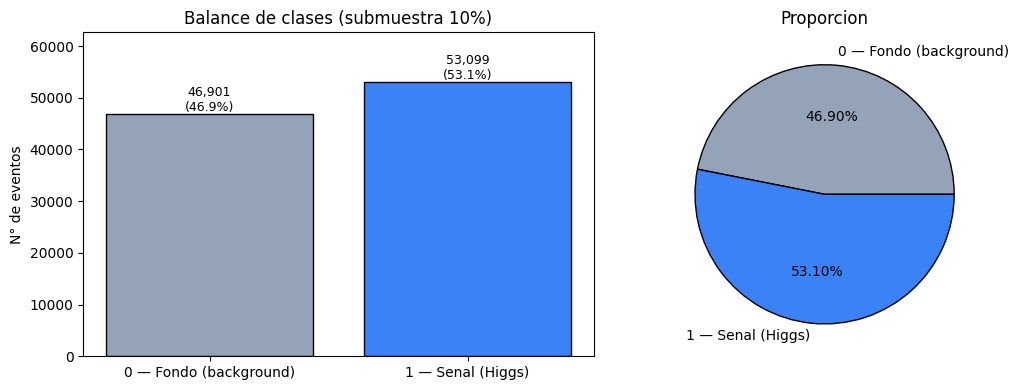


Razon de desbalance: 1.132 : 1
HIGGS esta practicamente balanceado, a diferencia de la Opcion A (fraude). Por lo tanto:
  - Accuracy SI es una metrica informativa aqui, pero se reportara junto a ROC-AUC,
    PR-AUC, F1 y la matriz de confusion para un analisis completo.
  - pos_weight en BCEWithLogitsLoss = n_neg/n_pos = 0.8833 (~1, correccion marginal).


In [9]:
FRAC_EDA = 0.10
df_eda = df.sample(frac=FRAC_EDA, random_state=SEED).reset_index(drop=True)
print(f"Submuestra de EDA: {len(df_eda):,} filas ({FRAC_EDA:.0%} del millon)")

# --- Balance de clases ---
conteo = df_eda["label"].value_counts().sort_index()
prop = df_eda["label"].value_counts(normalize=True).sort_index()
etiquetas = ["0 — Fondo (background)", "1 — Senal (Higgs)"]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(etiquetas, conteo.values, color=["#94a3b8", "#3b82f6"], edgecolor="black")
ax[0].set_title("Balance de clases (submuestra 10%)")
ax[0].set_ylabel("N° de eventos")
for i, v in enumerate(conteo.values):
    ax[0].text(i, v, f"{v:,}\n({prop.values[i]:.1%})", ha="center", va="bottom", fontsize=9)
ax[0].set_ylim(0, conteo.max() * 1.18)

ax[1].pie(conteo.values, labels=etiquetas, autopct="%1.2f%%", colors=["#94a3b8", "#3b82f6"],
          wedgeprops={"edgecolor": "black"})
ax[1].set_title("Proporcion")
plt.tight_layout()
guardar_figura("balance_clases.png")
plt.show()

ratio = conteo.max() / conteo.min()
print(f"\nRazon de desbalance: {ratio:.3f} : 1")
print("HIGGS esta practicamente balanceado, a diferencia de la Opcion A (fraude). Por lo tanto:")
print("  - Accuracy SI es una metrica informativa aqui, pero se reportara junto a ROC-AUC,")
print("    PR-AUC, F1 y la matriz de confusion para un analisis completo.")
print(f"  - pos_weight en BCEWithLogitsLoss = n_neg/n_pos = {conteo[0]/conteo[1]:.4f} (~1, correccion marginal).")

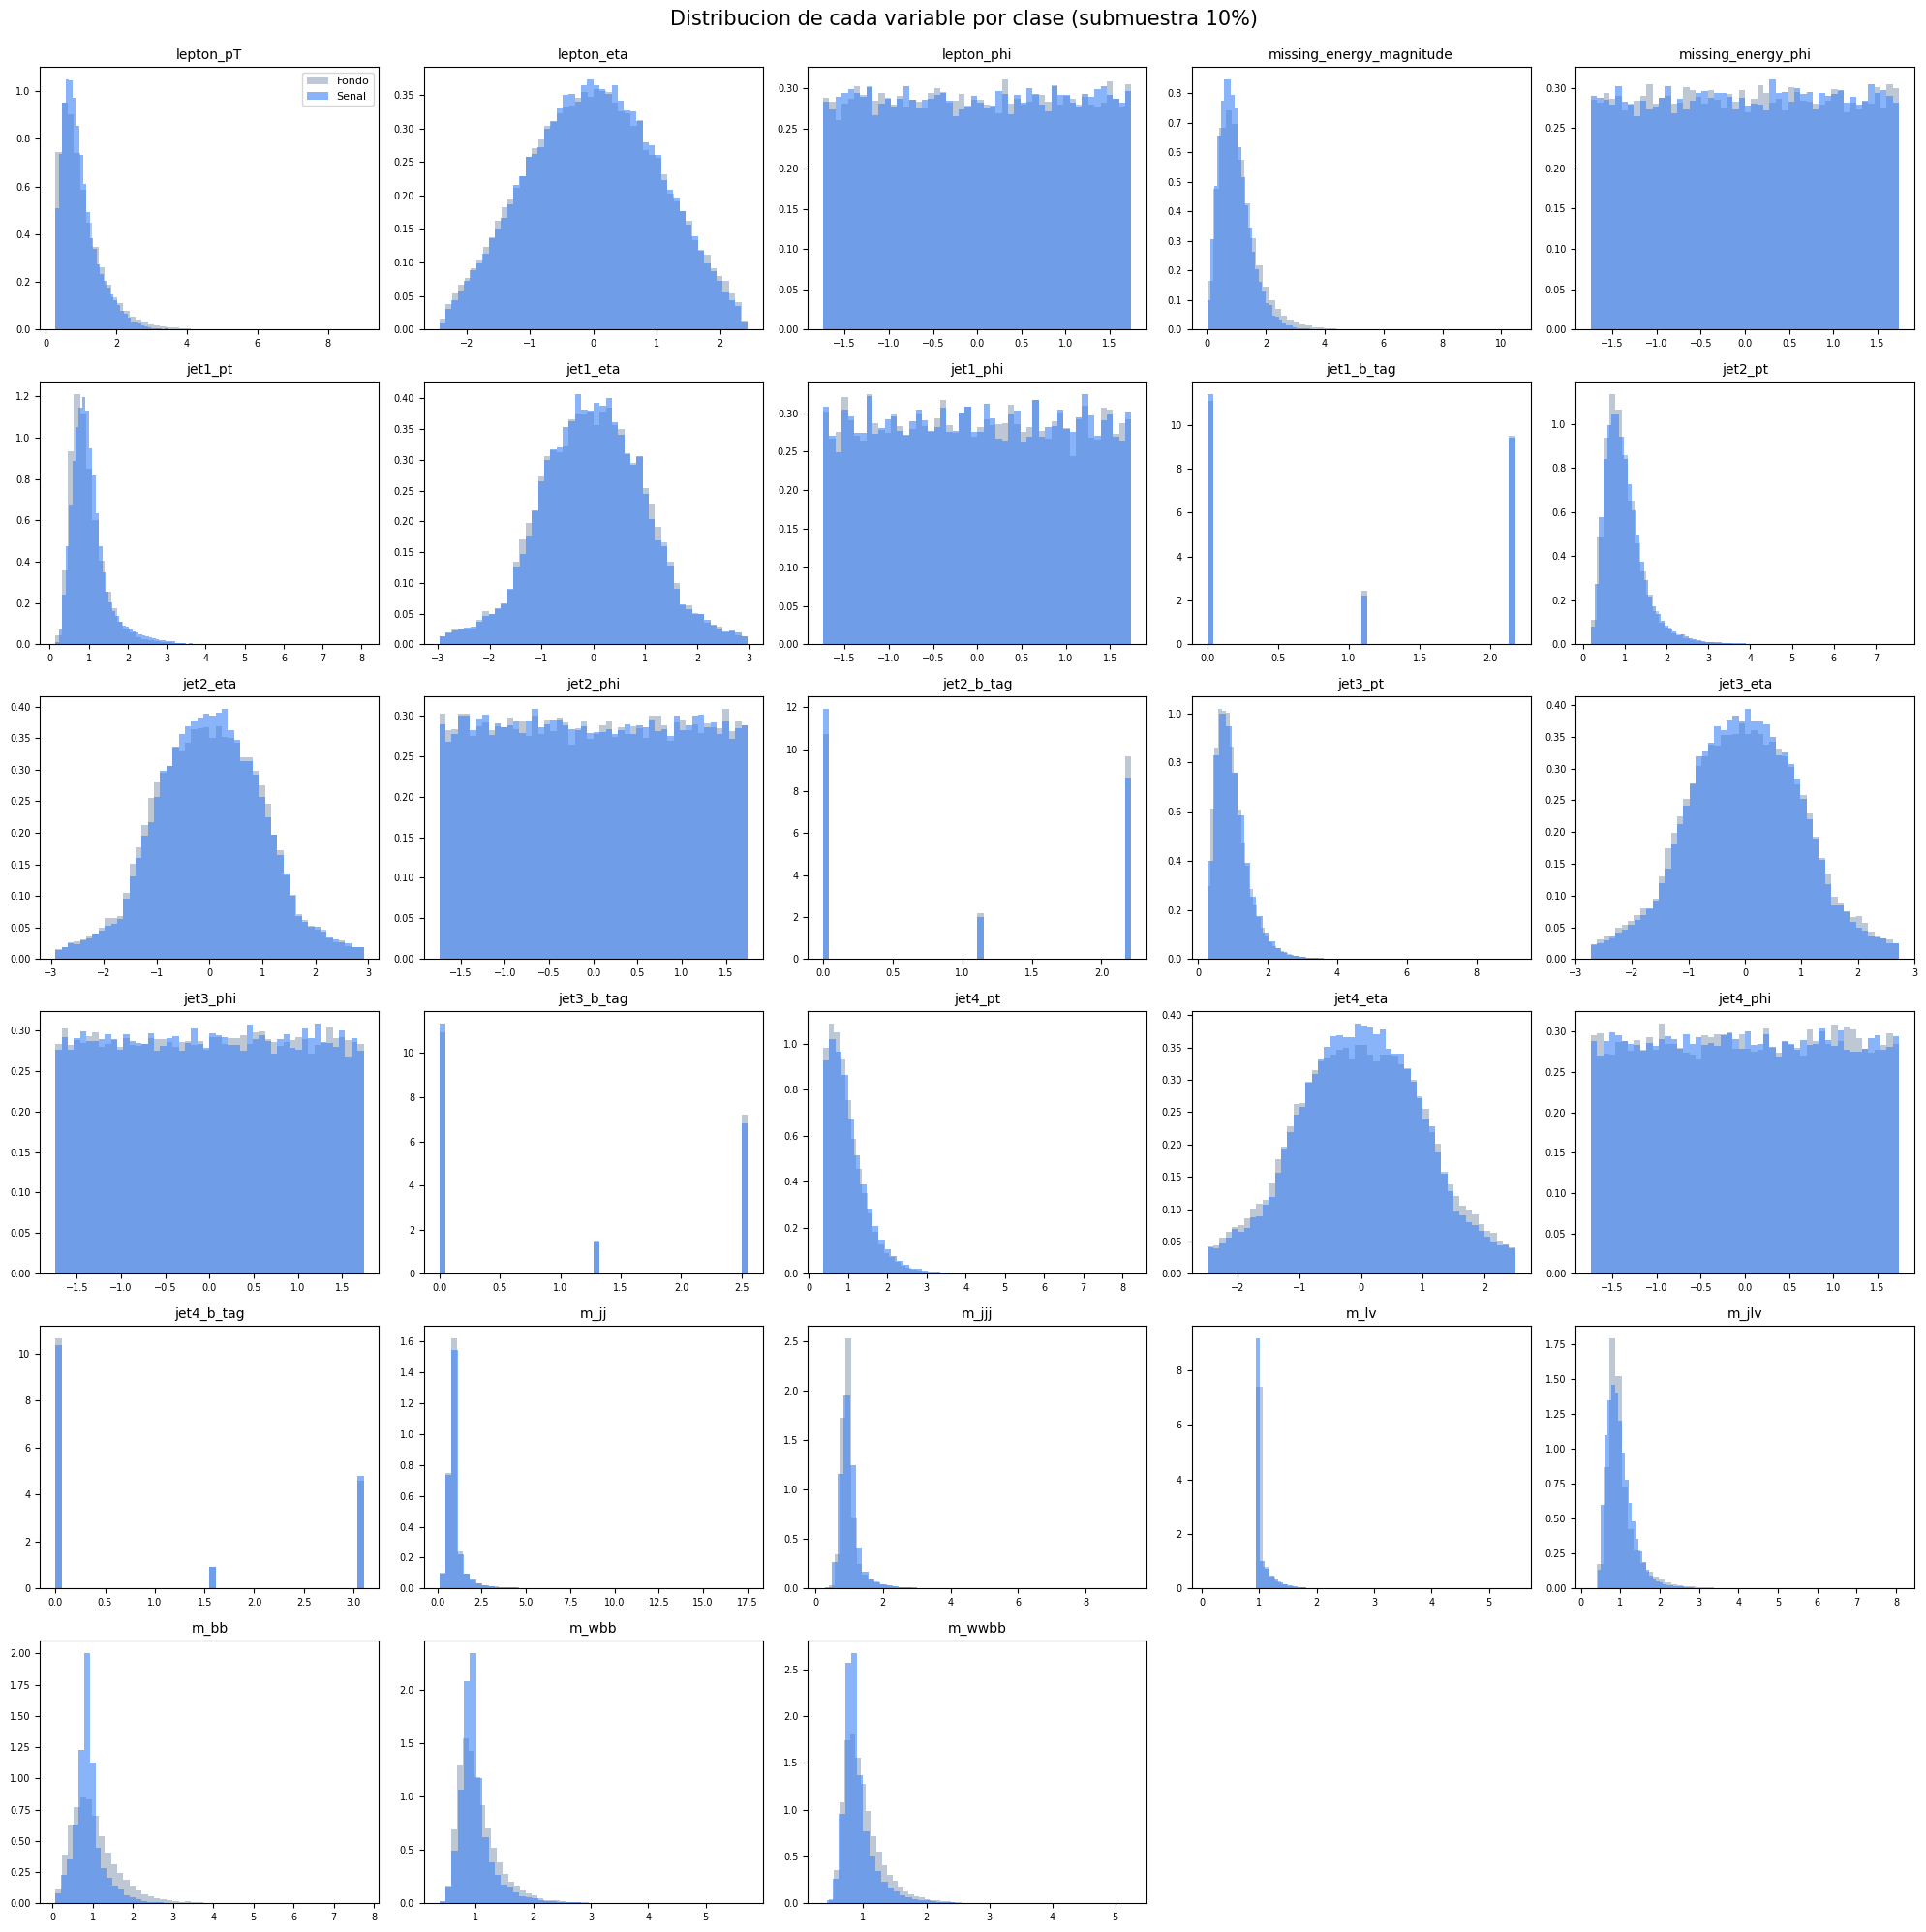

Lectura: las variables de BAJO nivel (pt, eta, phi) se superponen casi por completo entre
clases — individualmente casi no discriminan. Las de ALTO nivel (m_bb, m_wwbb, m_wbb)
muestran separaciones visibles. Esto justifica el uso de una red profunda: la senal esta
en las INTERACCIONES no lineales entre variables, no en ninguna variable aislada.


In [10]:
# --- Histogramas de las 28 variables ---
fig, axes = plt.subplots(6, 5, figsize=(20, 20))
axes = axes.ravel()

for i, col in enumerate(FEATURES):
    ax = axes[i]
    ax.hist(df_eda.loc[df_eda.label == 0, col], bins=50, alpha=0.6, label="Fondo",
            color="#94a3b8", density=True)
    ax.hist(df_eda.loc[df_eda.label == 1, col], bins=50, alpha=0.6, label="Senal",
            color="#3b82f6", density=True)
    ax.set_title(col, fontsize=10)
    ax.tick_params(labelsize=7)
    if i == 0:
        ax.legend(fontsize=8)

for j in range(len(FEATURES), len(axes)):
    axes[j].axis("off")

fig.suptitle("Distribucion de cada variable por clase (submuestra 10%)", fontsize=15, y=0.995)
plt.tight_layout()
guardar_figura("histogramas_variables.png", dpi=100)
plt.show()

print("Lectura: las variables de BAJO nivel (pt, eta, phi) se superponen casi por completo entre")
print("clases — individualmente casi no discriminan. Las de ALTO nivel (m_bb, m_wwbb, m_wbb)")
print("muestran separaciones visibles. Esto justifica el uso de una red profunda: la senal esta")
print("en las INTERACCIONES no lineales entre variables, no en ninguna variable aislada.")

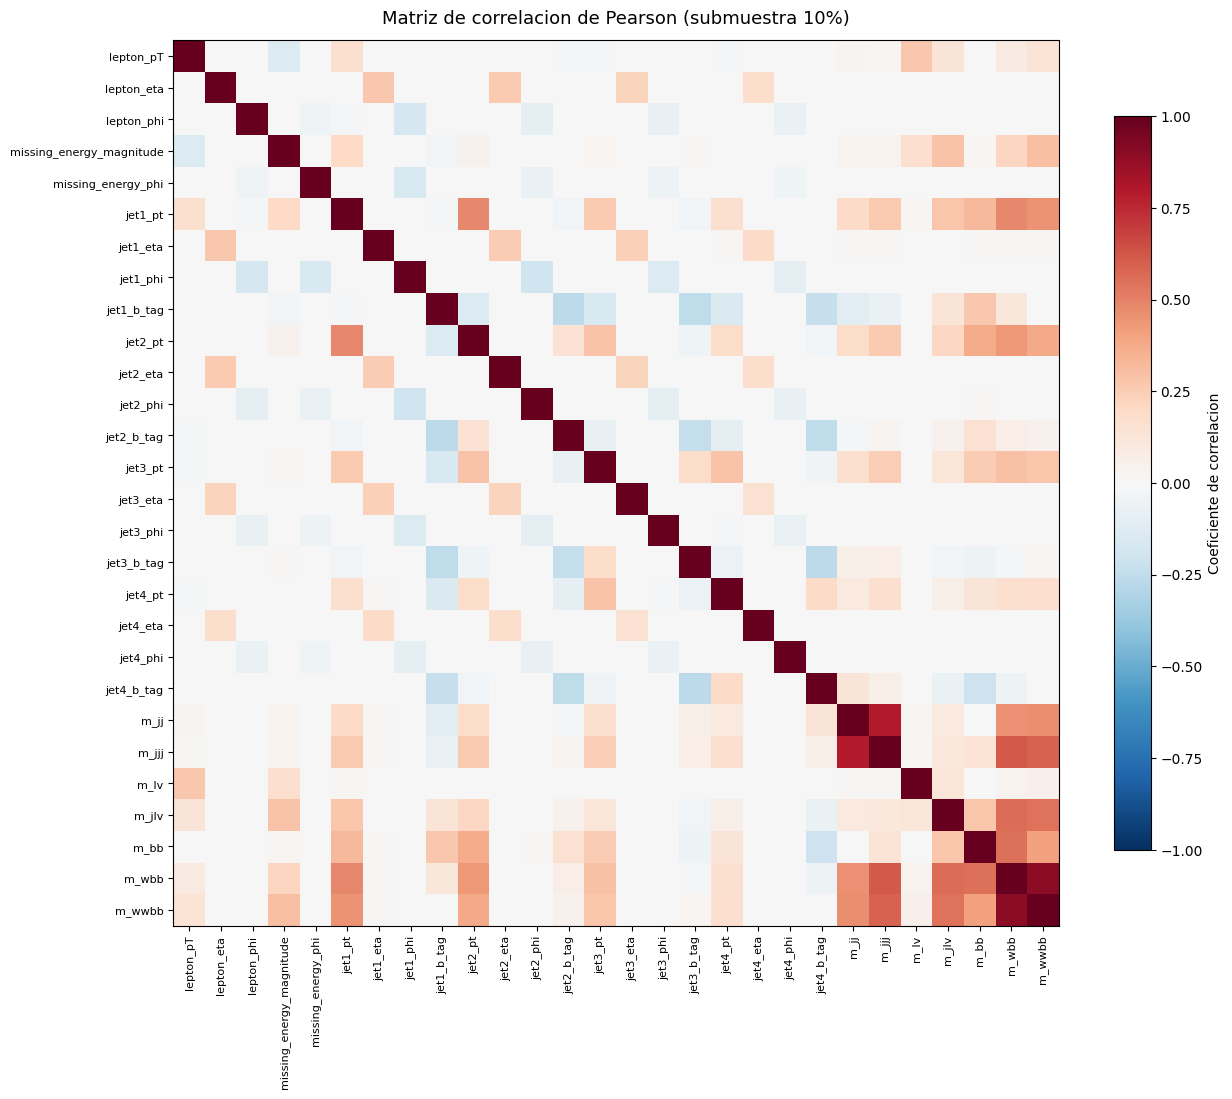

Pares de variables mas correlacionados:


,variable_1,variable_2,corr_abs
0,m_wwbb,m_wbb,0.895694
1,m_jjj,m_jj,0.794954
2,m_jjj,m_wbb,0.612428
3,m_wwbb,m_jjj,0.589468
4,m_wbb,m_jlv,0.558255
5,m_wbb,m_bb,0.549528
6,m_jlv,m_wwbb,0.539175
7,jet1_pt,jet2_pt,0.482258
8,jet1_pt,m_wbb,0.481485
9,m_wwbb,m_jj,0.466601



La alta colinealidad entre las masas invariantes es esperable (se calculan a partir de las
mismas magnitudes de bajo nivel) y es exactamente el motivo por el que el enunciado exige
regularizacion explicita: Dropout elevado, BatchNorm y Weight Decay en AdamW.


9

In [11]:
# --- Matriz de correlacion de Pearson ---
corr = df_eda[FEATURES].corr(method="pearson")

fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)))
ax.set_yticks(range(len(FEATURES)))
ax.set_xticklabels(FEATURES, rotation=90, fontsize=8)
ax.set_yticklabels(FEATURES, fontsize=8)
ax.set_title("Matriz de correlacion de Pearson (submuestra 10%)", fontsize=13, pad=12)
fig.colorbar(im, ax=ax, shrink=0.8, label="Coeficiente de correlacion")
plt.tight_layout()
guardar_figura("matriz_correlacion.png")
plt.show()

# Pares mas colineales
cm = corr.abs().copy()
np.fill_diagonal(cm.values, 0.0)
pares = (
    cm.unstack().sort_values(ascending=False)
    .drop_duplicates().head(10)
    .rename("corr_abs").reset_index()
    .rename(columns={"level_0": "variable_1", "level_1": "variable_2"})
)
print("Pares de variables mas correlacionados:")
display(pares)
print("\nLa alta colinealidad entre las masas invariantes es esperable (se calculan a partir de las")
print("mismas magnitudes de bajo nivel) y es exactamente el motivo por el que el enunciado exige")
print("regularizacion explicita: Dropout elevado, BatchNorm y Weight Decay en AdamW.")

del corr, cm
gc.collect()

---
# Celda 9 — Análisis no supervisado: PCA, t-SNE y K-Means

El análisis no supervisado responde una pregunta previa al entrenamiento de cualquier modelo:
**¿conforman las dos clases grupos separables en el espacio de las variables?** Si un método que no
accede a las etiquetas recuperara la separación entre señal y fondo, el problema admitiría
soluciones considerablemente más simples que una red profunda. El resultado esperado es el
contrario, y su verificación constituye la justificación cuantitativa de la arquitectura propuesta
en las fases siguientes.

Los tres métodos se aplican sobre los datos **escalados**, por ser sensibles a la escala de las
variables, y sobre submuestras de menor tamaño, dado que el costo computacional de t-SNE es
cuadrático en el número de observaciones.

Submuestra no supervisada: (20000, 28)


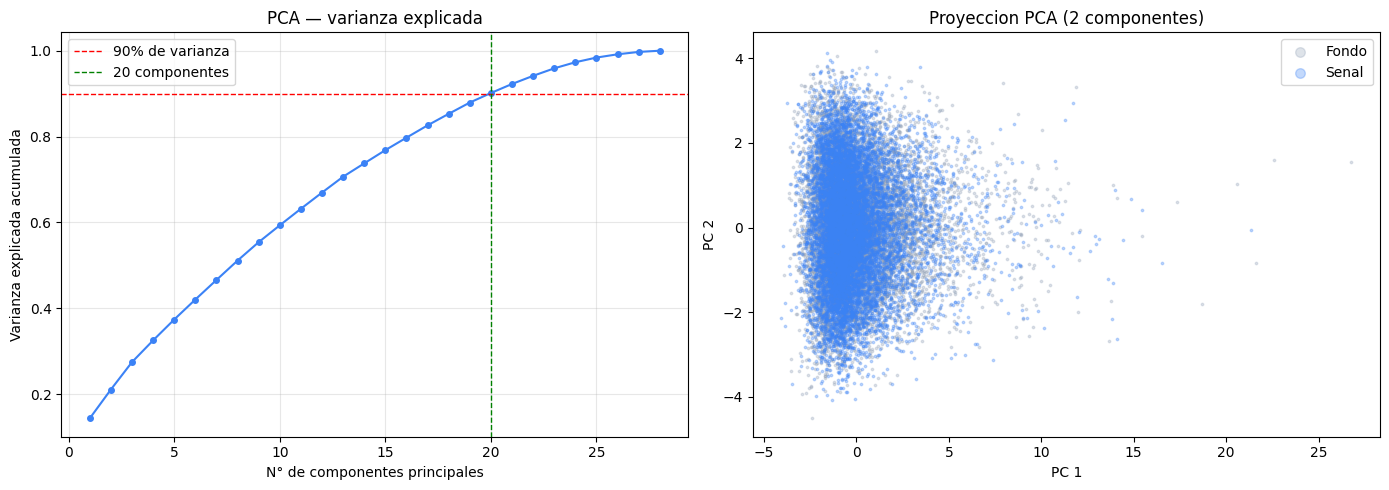

Se requieren 20 de 28 componentes para explicar el 90% de la varianza.
Las 2 primeras solo explican 21.1%: la informacion esta repartida, no hay
un subespacio lineal dominante y una reduccion lineal agresiva destruiria senal util.


50

In [12]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Submuestra escalada para el analisis no supervisado
N_NS = 20_000
idx_ns = rng.choice(len(X_train), size=N_NS, replace=False)
X_ns, y_ns = X_train[idx_ns], y_train[idx_ns]
print(f"Submuestra no supervisada: {X_ns.shape}")

# ---------- PCA ----------
pca_full = PCA(n_components=len(FEATURES), random_state=SEED).fit(X_ns)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)
n_90 = int(np.searchsorted(var_acum, 0.90) + 1)

X_pca = PCA(n_components=2, random_state=SEED).fit_transform(X_ns)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(range(1, len(var_acum) + 1), var_acum, "o-", color="#3b82f6", markersize=4)
ax[0].axhline(0.90, color="red", ls="--", lw=1, label="90% de varianza")
ax[0].axvline(n_90, color="green", ls="--", lw=1, label=f"{n_90} componentes")
ax[0].set_xlabel("N° de componentes principales")
ax[0].set_ylabel("Varianza explicada acumulada")
ax[0].set_title("PCA — varianza explicada")
ax[0].legend()
ax[0].grid(alpha=0.3)

for cls, color, lbl in [(0, "#94a3b8", "Fondo"), (1, "#3b82f6", "Senal")]:
    m = y_ns == cls
    ax[1].scatter(X_pca[m, 0], X_pca[m, 1], s=3, alpha=0.3, c=color, label=lbl)
ax[1].set_xlabel("PC 1"); ax[1].set_ylabel("PC 2")
ax[1].set_title("Proyeccion PCA (2 componentes)")
ax[1].legend(markerscale=4)
plt.tight_layout()
guardar_figura("pca.png")
plt.show()

print(f"Se requieren {n_90} de {len(FEATURES)} componentes para explicar el 90% de la varianza.")
print(f"Las 2 primeras solo explican {100*var_acum[1]:.1f}%: la informacion esta repartida, no hay")
print("un subespacio lineal dominante y una reduccion lineal agresiva destruiria senal util.")

del pca_full
gc.collect()

t-SNE calculado en 9s sobre 5,000 puntos


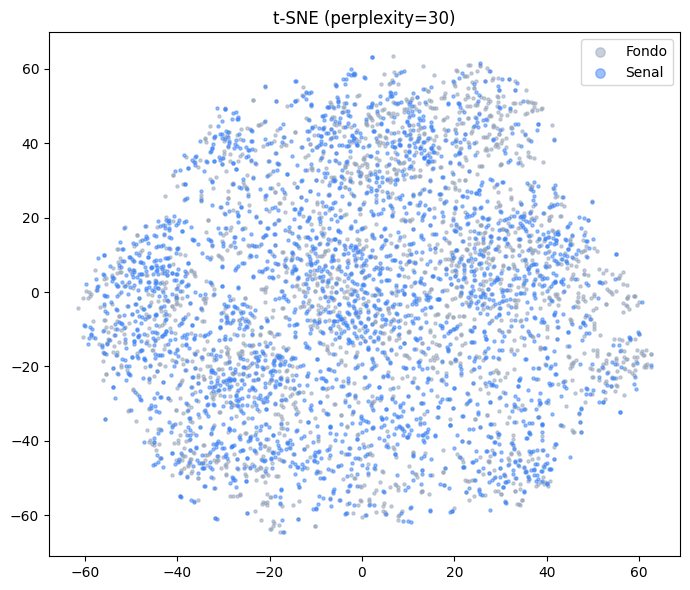

No aparecen dos islas limpias: senal y fondo estan entremezclados incluso bajo una
proyeccion no lineal. La frontera de decision es compleja y de alta dimension.


In [13]:
# ---------- t-SNE ----------
# Costo cuadratico: se limita a 5.000 puntos.
N_TSNE = 5_000
idx_t = rng.choice(N_NS, size=N_TSNE, replace=False)

t0 = time.time()
X_tsne = TSNE(
    n_components=2, perplexity=30, learning_rate="auto",
    init="pca", random_state=SEED,
).fit_transform(X_ns[idx_t])
print(f"t-SNE calculado en {time.time()-t0:.0f}s sobre {N_TSNE:,} puntos")

fig, ax = plt.subplots(figsize=(7, 6))
for cls, color, lbl in [(0, "#94a3b8", "Fondo"), (1, "#3b82f6", "Senal")]:
    m = y_ns[idx_t] == cls
    ax.scatter(X_tsne[m, 0], X_tsne[m, 1], s=5, alpha=0.5, c=color, label=lbl)
ax.set_title("t-SNE (perplexity=30)")
ax.legend(markerscale=3)
plt.tight_layout()
guardar_figura("tsne.png")
plt.show()

print("No aparecen dos islas limpias: senal y fondo estan entremezclados incluso bajo una")
print("proyeccion no lineal. La frontera de decision es compleja y de alta dimension.")

,k,silueta,ARI_vs_etiqueta_real
0,2,0.1862,0.0085
1,3,0.0423,NaN
2,4,0.0444,NaN
3,5,0.0403,NaN


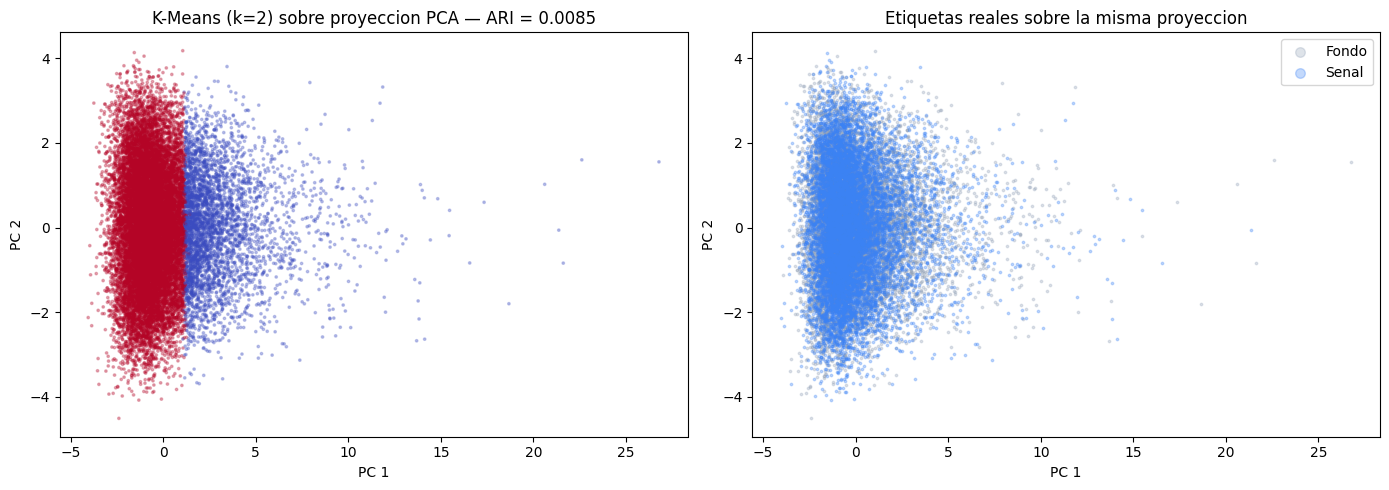

ARI de K-Means (k=2) frente a la etiqueta real: 0.0085
Un ARI cercano a 0 significa que la particion no supervisada NO coincide con la division
senal/fondo: la estructura geometrica dominante de los datos (dictada por la cinematica de
las colisiones) es independiente de la clase fisica que queremos predecir.

CONCLUSION DE LA FASE A: el problema NO es separable por metodos lineales ni por
agrupamiento por distancia. Se necesita aprendizaje supervisado profundo, que es
exactamente la hipotesis del paper original de Baldi et al. (2014).
[RAM] fin del analisis no supervisado    proceso:  0.94 GB | sistema: 21.18/34.16 GB (62%)


In [14]:
# ---------- K-Means ----------
N_SIL = 10_000  # silhouette_score es O(n^2) en memoria
idx_s = rng.choice(N_NS, size=N_SIL, replace=False)

resultados = []
for k in [2, 3, 4, 5]:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(X_ns)
    sil = silhouette_score(X_ns[idx_s], km.labels_[idx_s])
    ari = adjusted_rand_score(y_ns, km.labels_) if k == 2 else np.nan
    resultados.append({"k": k, "silueta": sil, "ARI_vs_etiqueta_real": ari})
    del km
    gc.collect()

tabla = pd.DataFrame(resultados)
display(tabla.round(4))

km2 = KMeans(n_clusters=2, random_state=SEED, n_init=10).fit(X_ns)
ari2 = adjusted_rand_score(y_ns, km2.labels_)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(X_pca[:, 0], X_pca[:, 1], s=3, alpha=0.3, c=km2.labels_, cmap="coolwarm")
ax[0].set_title(f"K-Means (k=2) sobre proyeccion PCA — ARI = {ari2:.4f}")
ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2")

for cls, color, lbl in [(0, "#94a3b8", "Fondo"), (1, "#3b82f6", "Senal")]:
    m = y_ns == cls
    ax[1].scatter(X_pca[m, 0], X_pca[m, 1], s=3, alpha=0.3, c=color, label=lbl)
ax[1].set_title("Etiquetas reales sobre la misma proyeccion")
ax[1].set_xlabel("PC 1"); ax[1].set_ylabel("PC 2")
ax[1].legend(markerscale=4)
plt.tight_layout()
guardar_figura("kmeans.png")
plt.show()

print(f"ARI de K-Means (k=2) frente a la etiqueta real: {ari2:.4f}")
print("Un ARI cercano a 0 significa que la particion no supervisada NO coincide con la division")
print("senal/fondo: la estructura geometrica dominante de los datos (dictada por la cinematica de")
print("las colisiones) es independiente de la clase fisica que queremos predecir.")
print("\nCONCLUSION DE LA FASE A: el problema NO es separable por metodos lineales ni por")
print("agrupamiento por distancia. Se necesita aprendizaje supervisado profundo, que es")
print("exactamente la hipotesis del paper original de Baldi et al. (2014).")

del km2, X_ns, y_ns, X_pca, X_tsne
gc.collect()
mem_report("fin del analisis no supervisado")

---
# Celda 10 — Resumen de artefactos generados

Verificación final de que todo lo que necesitan los notebooks 02 y 03 quedó persistido.

In [15]:
def listar(titulo, carpeta):
    """Lista los archivos de una carpeta, ignorando los marcadores de git."""
    print(titulo)
    print("=" * 72)
    archivos = sorted(p for p in carpeta.rglob("*")
                      if p.is_file() and p.name != ".gitkeep")
    if not archivos:
        print("  (vacia)")
    for p in archivos:
        print(f"  {str(p.relative_to(carpeta)):<45} {p.stat().st_size/1e6:>9.1f} MB")
    print()


# Artefactos pesados: reutilizables por los notebooks 02 y 03, no se versionan.
listar(f"DATOS PROCESADOS EN {PROC_DIR}", PROC_DIR)
listar(f"CHECKPOINTS EN {CKPT_DIR}", CKPT_DIR)
# Evidencia del informe: en el repositorio (versionada) y replicada en Drive.
for i, base in enumerate(DIRS_INFORME):
    etiqueta = "repositorio, versionada" if i == 0 else "copia de respaldo"
    listar(f"EVIDENCIA DEL INFORME EN {base}  [{etiqueta}]", base)

print("LISTO PARA EL NOTEBOOK 02 (modelos base):")
print(f"  - Features: {len(FEATURES)}")
print(f"  - Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")
print(f"  - Clases: binario (0 = fondo, 1 = senal)")
mem_report("final")


DATOS PROCESADOS EN G:\Mi unidad\Lab1-DL\data\processed
  higgs_1M.parquet                                   62.6 MB
  scaler.joblib                                       0.0 MB
  splits_escalados.npz                              113.0 MB

CHECKPOINTS EN G:\Mi unidad\Lab1-DL\checkpoints
  (vacia)

EVIDENCIA DEL INFORME EN C:\Users\Admin\Desktop\Magister Informatica\Aprendizaje Profundo\Lab1-DL\reports  [repositorio, versionada]
  figures\balance_clases.png                          0.1 MB
  figures\histogramas_variables.png                   0.1 MB
  figures\kmeans.png                                  0.3 MB
  figures\matriz_correlacion.png                      0.1 MB
  figures\pca.png                                     0.2 MB
  figures\tsne.png                                    0.2 MB
  profiling\comparacion_particiones.html              3.1 MB

EVIDENCIA DEL INFORME EN G:\Mi unidad\Lab1-DL\reports  [copia de respaldo]
  balance_clases.png                                  0.1 MB
  co

---
# Conclusiones de la Fase A

## 1. Gestión de memoria

El archivo original ocupa **7,5 GB descomprimidos**. La lectura por bloques de 1.000.000 de filas,
con casteo a `float32` y liberación explícita de cada bloque mediante `del` y `gc.collect()`,
mantuvo el consumo del proceso en un **máximo de 0,94 GB**, alcanzado al final del análisis no
supervisado. La cifra equivale a **menos del 13 % del tamaño del archivo** y a cerca del 8 % de los
12 GB que ofrece el nivel gratuito de Google Colab.

La progresión del consumo, registrada por la utilidad `mem_report()` en cada etapa, documenta el
comportamiento: 0,32 GB al inicio, 0,45 GB tras construir la submuestra de 1.000.000 de filas,
0,67 GB tras generar las particiones, 0,88 GB tras el reporte de profiling y 0,94 GB al cerrar el
análisis no supervisado. El crecimiento es gradual y ninguna etapa produce un salto abrupto, que es
el comportamiento esperado cuando ningún paso materializa el archivo completo en memoria.

Una lectura directa con `pd.read_csv()`, sin las medidas anteriores, habría intentado materializar
las 11.000.000 de filas en memoria. En `float64` —el tipo por defecto de pandas— eso representa
unos 2,5 GB solo para los datos, a los que se suman las estructuras intermedias que construye el
parser durante la lectura, con el agravante de que la descompresión del `.gz` ocurre en el mismo
proceso. El desenlace habitual es la terminación de la sesión por agotamiento de memoria
(*Out Of Memory*), que es precisamente el escenario que el enunciado exige evitar.

Dos decisiones adicionales redujeron el costo:

- **Casteo a `float32` en lugar de `float64`:** la mitad de memoria por valor, sin pérdida relevante
  de precisión en variables físicas que ya vienen reescaladas. El DataFrame resultante de
  1.000.000 × 29 ocupa **113 MB**.
- **Persistencia en `.parquet` en lugar de `.csv`:** el mismo contenido pesa **62,6 MB en disco**,
  un 45 % menos que en memoria, y la relectura conserva los tipos de dato, garantía que el formato
  CSV no ofrece.

## 2. Auditoría de particiones

Las tres particiones resultan homogéneas y el escalado se efectuó sin fugas de información. La
proporción de señal es de **52,954 % en Train, Validation y Test**, y el `StandardScaler` produce
media nula y desviación unitaria exactas **únicamente en Train**, mientras Validation
(+0,000495 / 1,002470) y Test (+0,000278 / 0,999187) quedan próximos pero no exactos. Conforme al
argumento desarrollado en el análisis de la auditoría, esa asimetría constituye la evidencia de
ausencia de *data leakage*. El detalle por variable consta en
`reports/profiling/comparacion_particiones.html`.

## 3. Hallazgos del análisis exploratorio

**El problema está balanceado.** La razón de desbalance es de **1,132 : 1** (52,95 % de señal), lo
que arroja un `pos_weight` de **0,8833** para `BCEWithLogitsLoss`, es decir, una corrección
marginal. Esta característica distingue a HIGGS de la Opción A —detección de fraude—, donde el
desbalance extremo invalida la exactitud como métrica. En el presente caso la exactitud **sí** es
informativa, aunque se reportará acompañada de ROC-AUC, PR-AUC, F1 y la matriz de confusión.
Evidencia: `reports/figures/balance_clases.png`.

**Ninguna variable discrimina de forma aislada.** En la grilla de histogramas
(`reports/figures/histogramas_variables.png`), las 21 variables cinemáticas de bajo nivel presentan
distribuciones prácticamente superpuestas entre señal y fondo. Únicamente las derivadas de alto
nivel —en particular `m_bb`, `m_wbb` y `m_wwbb`— exhiben separaciones apreciables, lo cual es
coherente con su construcción, dado que fueron diseñadas por especialistas del dominio con ese
propósito. La información discriminante no reside en variables individuales sino en las
**interacciones no lineales** entre ellas, que una red profunda puede modelar y un clasificador
lineal no.

**La colinealidad es alta y de origen estructural.** Los pares de mayor correlación corresponden
todos a masas invariantes (`reports/figures/matriz_correlacion.png`):

| Par | Correlación |
|---|---|
| `m_wwbb` – `m_wbb` | 0,896 |
| `m_jjj` – `m_jj` | 0,795 |
| `m_jjj` – `m_wbb` | 0,612 |
| `m_wwbb` – `m_jjj` | 0,589 |

El resultado es esperable, puesto que esas siete variables se calculan a partir de las mismas
magnitudes de bajo nivel: `m_wwbb` incorpora literalmente los mismos objetos que `m_wbb` más un
bosón W. No se eliminan, porque cada una aporta un encuadre distinto del mismo evento, pero la
redundancia obliga a **regularizar de forma explícita** mediante Dropout, Batch Normalization y
*weight decay* en AdamW, tal como prescribe el enunciado para la Opción B. En ausencia de
regularización, una red profunda sobre variables tan correlacionadas memoriza el ruido del conjunto
de entrenamiento.

## 4. Análisis no supervisado

Los tres métodos convergen en un mismo diagnóstico.

**PCA** (`reports/figures/pca.png`): se requieren **20 de 28 componentes** para explicar el 90 % de
la varianza, y las dos primeras capturan solo el **21,1 %**. No existe un subespacio lineal
dominante; la información se distribuye entre casi todas las direcciones, por lo que cualquier
reducción agresiva de dimensionalidad destruiría señal útil.

**t-SNE** (`reports/figures/tsne.png`): la proyección no lineal de 5.000 puntos, calculada en 10 s,
no produce dos regiones separadas. Señal y fondo aparecen entremezclados incluso preservando las
relaciones de vecindad local.

**K-Means** (`reports/figures/kmeans.png`): el índice de silueta es bajo para todos los valores de
*k* evaluados —**0,186 con k=2** y por debajo de 0,045 para k=3, 4 y 5—, lo que indica que los datos
no conforman grupos compactos ni bien separados. Más concluyente aún resulta el **ARI frente a la
etiqueta real, de 0,0085**, prácticamente nulo: el agrupamiento por distancia euclidiana no guarda
relación con la división física entre señal y fondo. La estructura geométrica dominante del espacio
de variables está determinada por la cinemática general de las colisiones y no por el proceso
físico que las originó.

## 5. Implicancias para las Fases B y C

El problema **no es separable mediante métodos lineales ni por agrupamiento por distancia**. Lejos
de constituir un resultado negativo, esa constatación es la justificación cuantitativa del diseño
que sigue: si K-Means hubiera recuperado la división señal/fondo, el recurso a una red profunda
sería innecesario.

De los hallazgos anteriores se desprenden cinco decisiones de diseño:

1. **Arquitectura FFNN profunda** con Batch Normalization y Dropout, capaz de modelar las
   interacciones no lineales entre variables que el análisis lineal no detecta.
2. **Regularización explícita** mediante *weight decay* en AdamW, requerida por la colinealidad
   documentada en la sección 3.
3. **`BCEWithLogitsLoss` con `pos_weight` ≈ 0,88**, corrección menor dado el balance de clases.
4. **ROC-AUC y PR-AUC como métricas principales**, acompañadas de F1 y de la matriz de confusión.
5. **Ensamble Bagging + Stacking** con **3 modelos base** —el máximo del rango que el enunciado
   fija para un grupo de un integrante— entrenados sobre muestras Bootstrap distintas y combinados
   mediante una meta-red de pesos entrenables.

El planteamiento reproduce, a escala de laboratorio, la hipótesis central del trabajo de Baldi,
Sadowski y Whiteson (2014): que el aprendizaje profundo puede extraer de las variables crudas del
detector la información que los físicos obtenían mediante la construcción manual de variables
derivadas.